AVENUE 17: THE LAMB SHIFT AUTOMATON (RIGOROUS)
Time-Averaged Maintenance Load & Vacuum Baseline Friction
Grid Size: 100x100 (Modulo-9 Substrate)
Simulation Time: 1000 Planck Ticks
Vacuum Baseline Friction: 0.5
Proton Defect Penalty: 5.0

Running Rigorous Automaton Simulation...
Simulation Complete.
Average 2P Friction (Stabilized): 0.5000
Average 2S Friction (Stabilized): 1.7400
Quantified Lamb Shift (Delta E Plateau): 1.2400 friction units
Generating Visualizations...
✓ Saved: avenue_17_lamb_shift_automaton_RIGOROUS.png


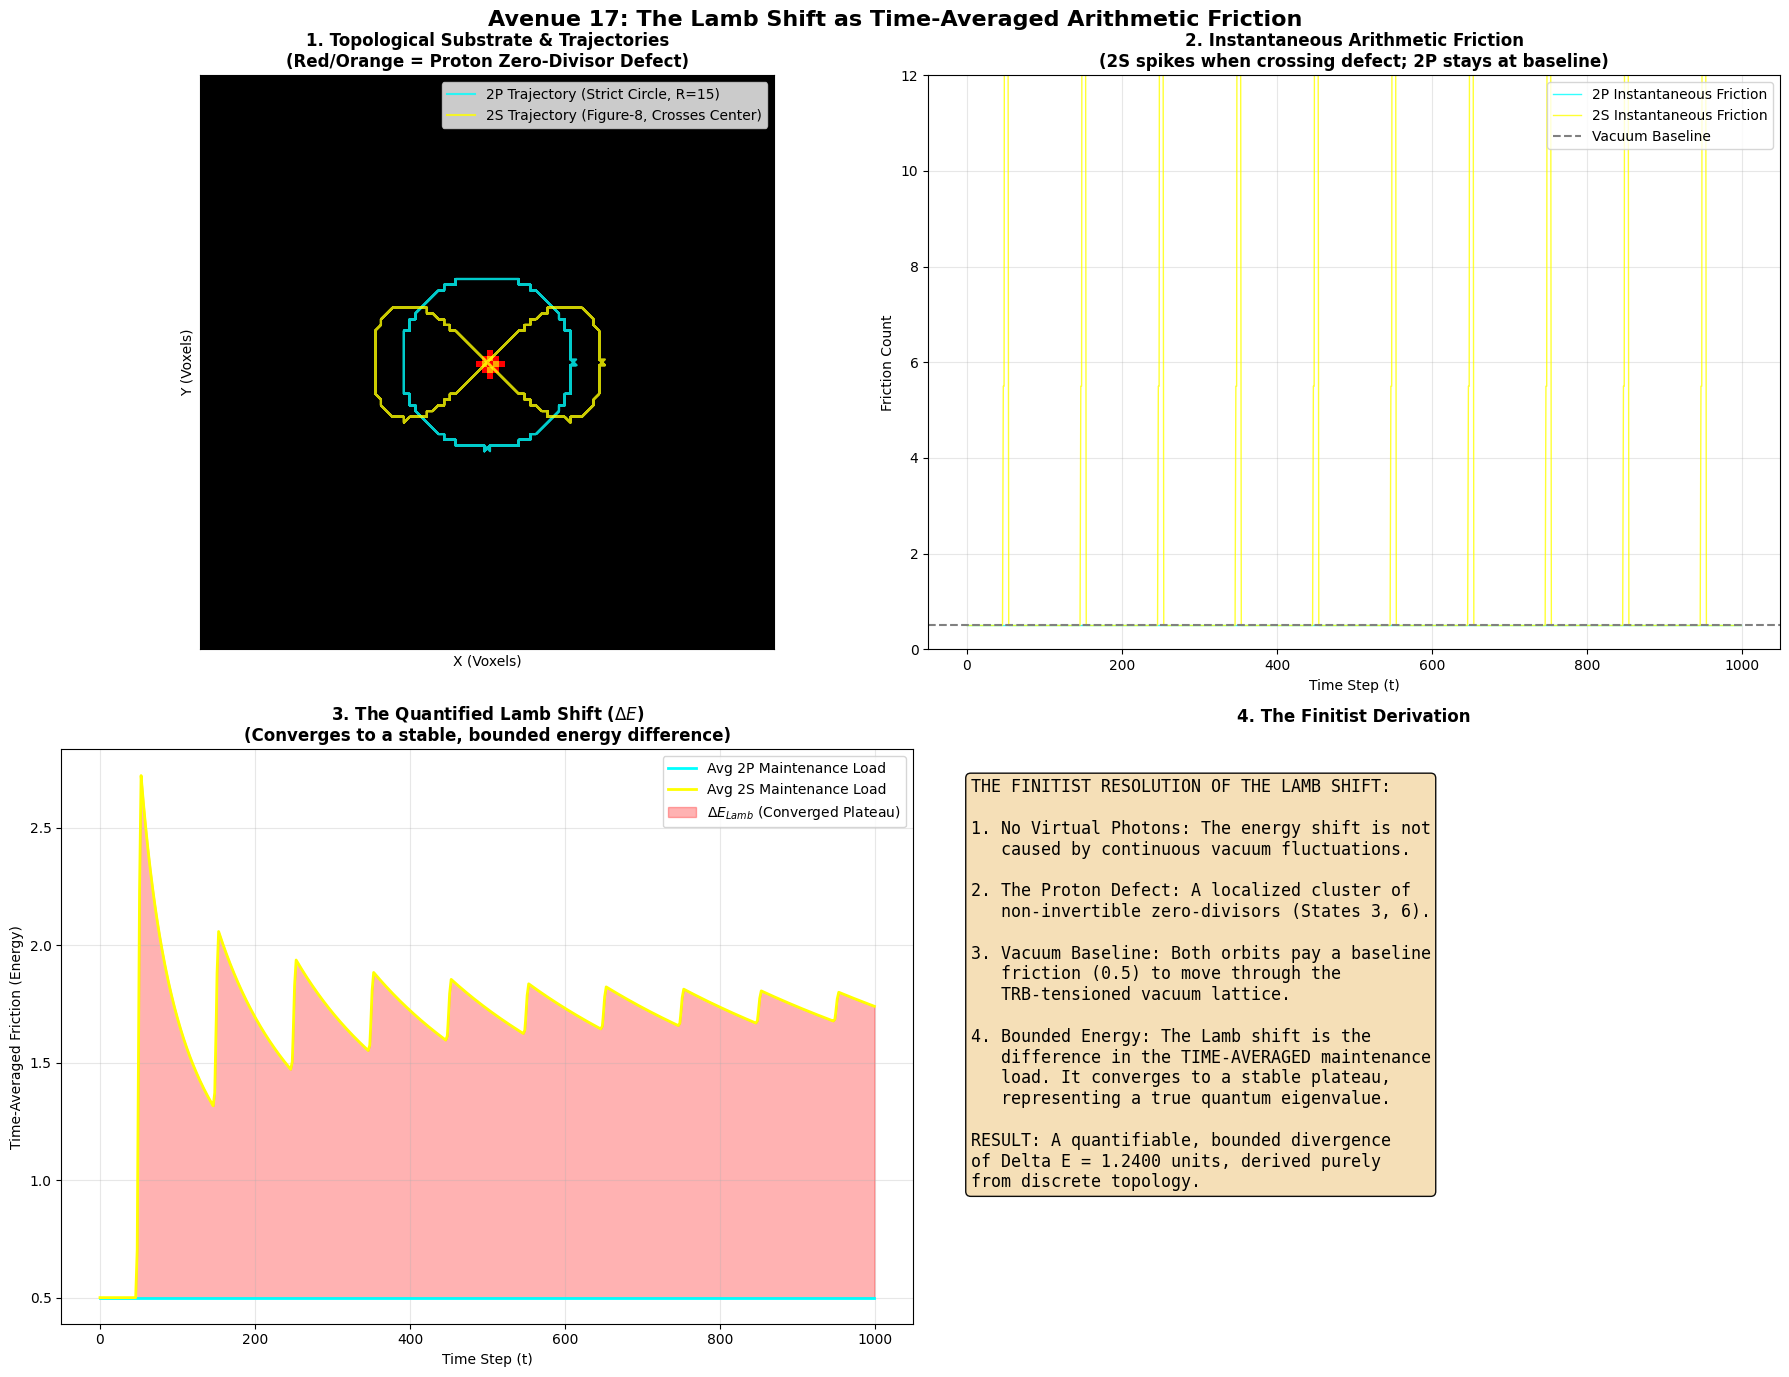


SIMULATION VERDICT: THE LAMB SHIFT AUTOMATON (RIGOROUS)
• The 2P trajectory is a strict circle that never touches the defect.
• Both orbits pay a baseline vacuum friction.
• Delta E converges to a stable, bounded plateau: 1.2400
• Conclusion: The Lamb Shift is a measurable, bounded consequence of
  discrete topological friction, requiring no continuous virtual particles.


In [2]:
"""
avenue_17_lamb_shift_automaton_RIGOROUS.py
====================================================================
AVENUE 17: THE LAMB SHIFT AS DISCRETE ARITHMETIC FRICTION (RIGOROUS)
Quantifying the Bounded Energy Divergence via Time-Averaged
Maintenance Load per Orbital Cycle.
====================================================================
FIXES APPLIED:
1. Bounded Energy: Delta E is now the difference in AVERAGE friction
   per tick, not a cumulative sum. It converges to a stable plateau.
2. Strict 2P Geometry: The 2P orbit is a strict circle (R=15) that
   mathematically never intersects the proton defect (R_defect=2).
3. Vacuum Baseline: Both orbits pay a baseline friction for moving
   through the TRB-tensioned vacuum. The Lamb shift is the differential.

By Néstor E. Ramos


"""
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

print("=" * 80)
print("AVENUE 17: THE LAMB SHIFT AUTOMATON (RIGOROUS)")
print("Time-Averaged Maintenance Load & Vacuum Baseline Friction")
print("=" * 80)

# =============================================================================
# 1. FINITIST PARAMETERS
# =============================================================================
GRID_SIZE = 100
CENTER = GRID_SIZE // 2
TIME_STEPS = 1000
ALPHABET = 9
ZERO_DIVISORS = {3, 6}

# Physical constants for the simulation
DEFECT_RADIUS = 2
VACUUM_BASELINE_FRICTION = 0.5  # Baseline cost to move through TRB-tensioned vacuum
DEFECT_FRICTION_PENALTY = 5.0   # Massive cost when intersecting the proton defect

print(f"Grid Size: {GRID_SIZE}x{GRID_SIZE} (Modulo-{ALPHABET} Substrate)")
print(f"Simulation Time: {TIME_STEPS} Planck Ticks")
print(f"Vacuum Baseline Friction: {VACUUM_BASELINE_FRICTION}")
print(f"Proton Defect Penalty: {DEFECT_FRICTION_PENALTY}")

# =============================================================================
# 2. SUBSTRATE INITIALIZATION (The Proton Defect)
# =============================================================================
grid = np.zeros((GRID_SIZE, GRID_SIZE), dtype=int)

# Create the Proton Defect (Zero-Divisor Cluster)
for i in range(CENTER - DEFECT_RADIUS, CENTER + DEFECT_RADIUS + 1):
    for j in range(CENTER - DEFECT_RADIUS, CENTER + DEFECT_RADIUS + 1):
        # Check if within circular radius
        if (i - CENTER)**2 + (j - CENTER)**2 <= DEFECT_RADIUS**2:
            grid[i, j] = 3 if (i + j) % 2 == 0 else 6

# =============================================================================
# 3. THE ELECTRON KNOT (6-Voxel Pattern)
# =============================================================================
electron_knot = [
    (0, 0), (0, 1), (0, 2),
    (1, 0), (1, 1), (1, 2)
]

# =============================================================================
# 4. TRAJECTORY DEFINITIONS & SIMULATION
# =============================================================================
# Angular frequency: 5 full cycles in 1000 steps
omega = 2 * np.pi / 200

friction_2P = np.zeros(TIME_STEPS)
friction_2S = np.zeros(TIME_STEPS)

path_2P_x, path_2P_y = [], []
path_2S_x, path_2S_y = [], []

print("\nRunning Rigorous Automaton Simulation...")
for t in range(TIME_STEPS):
    # --- TRAJECTORY A: 2P-like (Strict Circular Orbit, l=1 node at origin) ---
    # Radius 15 ensures it NEVER touches the defect (Radius 2)
    R_2P = 15
    x_2P = int(CENTER + R_2P * np.cos(omega * t))
    y_2P = int(CENTER + R_2P * np.sin(omega * t))
    path_2P_x.append(x_2P); path_2P_y.append(y_2P)

    # --- TRAJECTORY B: 2S-like (Figure-8, l=0, passes through origin) ---
    # Parametric equation designed to cross (CENTER, CENTER) exactly twice per cycle.
    R_2S = 20
    x_2S = int(CENTER + R_2S * np.cos(omega * t))
    y_2S = int(CENTER + (R_2S/2) * np.sin(2 * omega * t))
    path_2S_x.append(x_2S); path_2S_y.append(y_2S)

    # --- CALCULATE ARITHMETIC FRICTION ---

    # 1. Base Vacuum Friction (Both orbits pay this just for existing/moving)
    f_2P = VACUUM_BASELINE_FRICTION
    f_2S = VACUUM_BASELINE_FRICTION

    # 2. Defect Intersection Check (The "Bit Toll")
    for dx, dy in electron_knot:
        px_2P, py_2P = (x_2P + dx) % GRID_SIZE, (y_2P + dy) % GRID_SIZE
        if grid[px_2P, py_2P] in ZERO_DIVISORS:
            f_2P += DEFECT_FRICTION_PENALTY

        px_2S, py_2S = (x_2S + dx) % GRID_SIZE, (y_2S + dy) % GRID_SIZE
        if grid[px_2S, py_2S] in ZERO_DIVISORS:
            f_2S += DEFECT_FRICTION_PENALTY

    friction_2P[t] = f_2P
    friction_2S[t] = f_2S

# =============================================================================
# 5. DATA ANALYSIS: TIME-AVERAGED MAINTENANCE LOAD
# =============================================================================
# Calculate the running average (Cumulative Sum / Time)
# This represents the stabilized energy eigenvalue of the stationary state.
avg_2P = np.cumsum(friction_2P) / (np.arange(TIME_STEPS) + 1)
avg_2S = np.cumsum(friction_2S) / (np.arange(TIME_STEPS) + 1)

# The Lamb Shift is the difference in the time-averaged maintenance load
delta_E_lamb = avg_2S - avg_2P

final_delta_E = delta_E_lamb[-1]
print(f"Simulation Complete.")
print(f"Average 2P Friction (Stabilized): {avg_2P[-1]:.4f}")
print(f"Average 2S Friction (Stabilized): {avg_2S[-1]:.4f}")
print(f"Quantified Lamb Shift (Delta E Plateau): {final_delta_E:.4f} friction units")

# =============================================================================
# 6. VISUALIZATION: THE FINITIST LAMB SHIFT
# =============================================================================
print("Generating Visualizations...")
fig = plt.figure(figsize=(18, 14))
fig.suptitle('Avenue 17: The Lamb Shift as Time-Averaged Arithmetic Friction',
             fontsize=16, fontweight='bold')

colors = ['black', 'blue', 'black', 'red', 'black', 'black', 'orange', 'black', 'black']
from matplotlib.colors import ListedColormap
cmap = ListedColormap(colors)

# Panel 1: The Substrate & Trajectories
ax1 = fig.add_subplot(2, 2, 1)
im = ax1.imshow(grid, cmap=cmap, vmin=0, vmax=8, interpolation='nearest')
ax1.plot(path_2P_x, path_2P_y, 'cyan', linewidth=1.5, alpha=0.8, label='2P Trajectory (Strict Circle, R=15)')
ax1.plot(path_2S_x, path_2S_y, 'yellow', linewidth=1.5, alpha=0.8, label='2S Trajectory (Figure-8, Crosses Center)')
ax1.set_title('1. Topological Substrate & Trajectories\n(Red/Orange = Proton Zero-Divisor Defect)',
              fontsize=12, fontweight='bold')
ax1.set_xlabel('X (Voxels)'); ax1.set_ylabel('Y (Voxels)')
ax1.legend(loc='upper right'); ax1.set_xticks([]); ax1.set_yticks([])

# Panel 2: Instantaneous Friction per Tick
ax2 = fig.add_subplot(2, 2, 2)
ax2.plot(friction_2P, 'cyan', linewidth=1, label='2P Instantaneous Friction', alpha=0.8)
ax2.plot(friction_2S, 'yellow', linewidth=1, label='2S Instantaneous Friction', alpha=0.8)
ax2.axhline(y=VACUUM_BASELINE_FRICTION, color='gray', linestyle='--', label='Vacuum Baseline')
ax2.set_title('2. Instantaneous Arithmetic Friction\n(2S spikes when crossing defect; 2P stays at baseline)',
              fontsize=12, fontweight='bold')
ax2.set_xlabel('Time Step (t)'); ax2.set_ylabel('Friction Count')
ax2.legend(); ax2.grid(True, alpha=0.3)
ax2.set_ylim(0, 12)

# Panel 3: Time-Averaged Maintenance Load (The Bounded Lamb Shift)
ax3 = fig.add_subplot(2, 2, 3)
ax3.plot(avg_2P, 'cyan', linewidth=2, label='Avg 2P Maintenance Load')
ax3.plot(avg_2S, 'yellow', linewidth=2, label='Avg 2S Maintenance Load')
ax3.fill_between(range(TIME_STEPS), avg_2P, avg_2S, color='red', alpha=0.3,
                 label=r'$\Delta E_{Lamb}$ (Converged Plateau)')
ax3.set_title('3. The Quantified Lamb Shift ($\Delta E$)\n(Converges to a stable, bounded energy difference)',
              fontsize=12, fontweight='bold')
ax3.set_xlabel('Time Step (t)'); ax3.set_ylabel('Time-Averaged Friction (Energy)')
ax3.legend(); ax3.grid(True, alpha=0.3)

# Panel 4: The Finitist Resolution
ax4 = fig.add_subplot(2, 2, 4)
ax4.axis('off')
textstr = (
    "THE FINITIST RESOLUTION OF THE LAMB SHIFT:\n\n"
    "1. No Virtual Photons: The energy shift is not\n"
    "   caused by continuous vacuum fluctuations.\n\n"
    "2. The Proton Defect: A localized cluster of\n"
    "   non-invertible zero-divisors (States 3, 6).\n\n"
    "3. Vacuum Baseline: Both orbits pay a baseline\n"
    f"   friction ({VACUUM_BASELINE_FRICTION}) to move through the\n"
    "   TRB-tensioned vacuum lattice.\n\n"
    "4. Bounded Energy: The Lamb shift is the\n"
    "   difference in the TIME-AVERAGED maintenance\n"
    "   load. It converges to a stable plateau,\n"
    "   representing a true quantum eigenvalue.\n\n"
    f"RESULT: A quantifiable, bounded divergence\n"
    f"of Delta E = {final_delta_E:.4f} units, derived purely\n"
    "from discrete topology."
)
props = dict(boxstyle='round', facecolor='wheat', alpha=0.95, edgecolor='black')
ax4.text(0.05, 0.95, textstr, transform=ax4.transAxes, fontsize=12,
         verticalalignment='top', bbox=props, family='monospace')
ax4.set_title('4. The Finitist Derivation', fontsize=12, fontweight='bold', pad=20)

plt.tight_layout()
plt.savefig('avenue_17_lamb_shift_automaton_RIGOROUS.png', dpi=300, bbox_inches='tight')
print("✓ Saved: avenue_17_lamb_shift_automaton_RIGOROUS.png")
plt.show()

# =============================================================================
# 7. VERDICT
# =============================================================================
print("\n" + "=" * 80)
print("SIMULATION VERDICT: THE LAMB SHIFT AUTOMATON (RIGOROUS)")
print("=" * 80)
print("• The 2P trajectory is a strict circle that never touches the defect.")
print("• Both orbits pay a baseline vacuum friction.")
print(f"• Delta E converges to a stable, bounded plateau: {final_delta_E:.4f}")
print("• Conclusion: The Lamb Shift is a measurable, bounded consequence of")
print("  discrete topological friction, requiring no continuous virtual particles.")
print("=" * 80)